In [24]:
print("Hello World")

Hello World


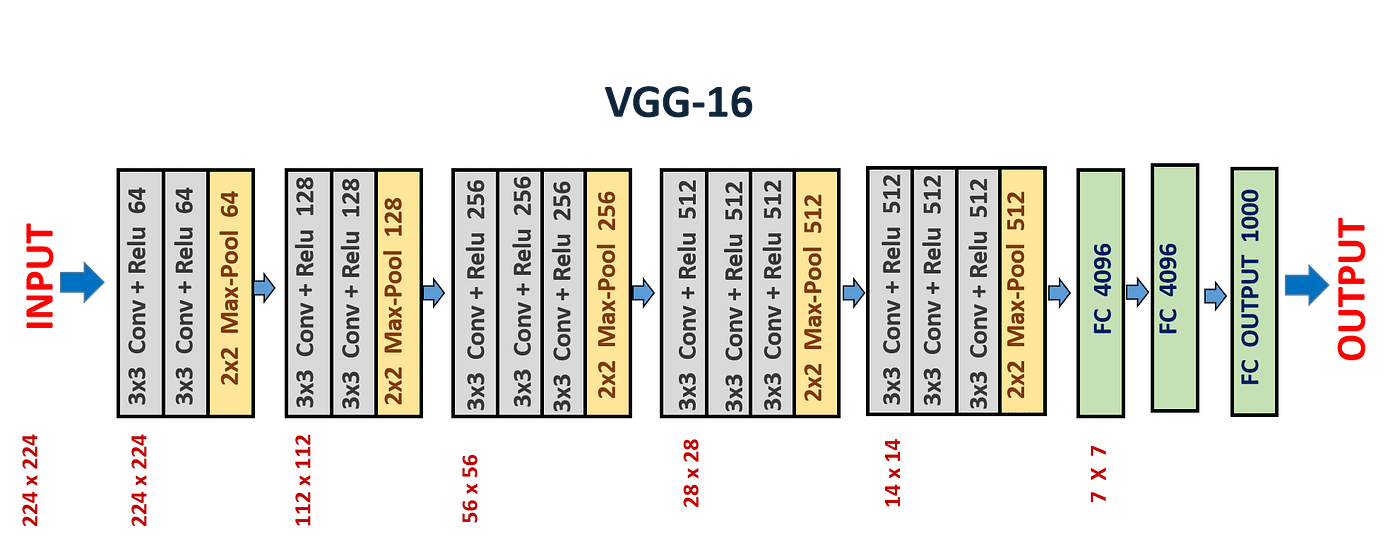

In [25]:
from PIL import Image

img = Image.open("architecture.png")
img

### In VGG16, there are 13 Convolution blocks and 5 MaxPooling blocks with 3 Fully Connected layers at the end


In [26]:
from typing import Any
import torch
import torch.nn as nn
import torch.optim as optim

# Input : 3 × 224 × 224

In [27]:
num_classes = 5

# Defining all the Max Pooling Layers for the architecture

config = [
    64, 64, "M",    
    128, 128, "M",
    256, 256, 256, "M",
    512, 512, 512, "M",
    512, 512, 512, "M"
]

# M stands for Max Pooling Layer
"""
64, 64, "M"

Conv2D(3 -> 64)
ReLU
Conv2D(64 -> 64)
ReLU
MaxPool2D

"""

'\n64, 64, "M"\n\nConv2D(3 -> 64)\nReLU\nConv2D(64 -> 64)\nReLU\nMaxPool2D\n\n'

In [28]:
# create the layers
def make_layers(config):
    layers = []
    in_channels = 3  # initial

    for x in config:

        if x == "M":

            layers.append(nn.MaxPool2d(kernel_size=2, stride=2))

        else:

            layers.append(nn.Conv2d(in_channels, x, kernel_size=3, padding=1))
            layers.append(nn.ReLU(inplace=True))
            in_channels = x

    return nn.Sequential(*layers)

In [29]:
class VGG16(nn.Module):
    def __init__(self, *args: Any, **kwargs: Any) -> None:
        super().__init__(*args, **kwargs)

        self.features = make_layers(config)

        self.avgpool = nn.AdaptiveAvgPool2d((7,7))

        # Classifier
        self.classifier = nn.Sequential(
            nn.Linear(512 * 7 * 7, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),

            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),

            nn.Linear(4096, num_classes)

        )

    def forward(self, x):
        x = self.features(x)

        x = self.avgpool(x)

        x = torch.flatten(x, 1)

        x = self.classifier(x)

        return x

In [30]:
model = VGG16()

In [31]:
total_params = sum(
    p.numel() for p in model.parameters()
)

print(f"Total parameters: {total_params:,}")

Total parameters: 134,281,029


In [32]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("alxmamaev/flowers-recognition")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\birat\.cache\kagglehub\datasets\alxmamaev\flowers-recognition\versions\2


In [33]:
# Splitting data into train, val and test
import os
import random
import shutil
from pathlib import Path

# Original dataset directory
path = kagglehub.dataset_download("alxmamaev/flowers-recognition")

source_dir = Path(path) / "flowers"

# Destination directory
output_dir = Path("flower_dataset")

# Split ratios
train_ratio = 0.70
val_ratio = 0.15
test_ratio = 0.15

# Reproducibility
random.seed(42)

# Supported image formats
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Get all class directories
classes = [d for d in source_dir.iterdir() if d.is_dir()]

for class_dir in classes:

    class_name = class_dir.name

    # Get images belonging to this class
    images = [
        f for f in class_dir.iterdir()
        if f.is_file() and f.suffix.lower() in image_extensions
    ]

    # Shuffle images
    random.shuffle(images)

    # Calculate split sizes
    total = len(images)

    train_end = int(total * train_ratio)
    val_end = train_end + int(total * val_ratio)

    train_images = images[:train_end]
    val_images = images[train_end:val_end]
    test_images = images[val_end:]

    # Create destination directories
    for split in ["train", "val", "test"]:
        (output_dir / split / class_name).mkdir(
            parents=True,
            exist_ok=True
        )

    # Copy images
    for split, split_images in [
        ("train", train_images),
        ("val", val_images),
        ("test", test_images)
    ]:

        for image in split_images:

            destination = (
                output_dir / split / class_name / image.name
            )

            shutil.copy2(image, destination)

    print(
        f"{class_name}: "
        f"Train={len(train_images)}, "
        f"Val={len(val_images)}, "
        f"Test={len(test_images)}"
    )

print("Dataset splitting completed!")

daisy: Train=534, Val=114, Test=116
dandelion: Train=736, Val=157, Test=159
rose: Train=548, Val=117, Test=119
sunflower: Train=513, Val=109, Test=111
tulip: Train=688, Val=147, Test=149
Dataset splitting completed!


In [38]:
from pathlib import Path

print("Current directory:", Path.cwd())

print("\nTraining directory:")
print(list(Path("flower_dataset/train").iterdir()))

Current directory: c:\MachineLearning\Paper Implementation\VGGNet

Training directory:
[WindowsPath('flower_dataset/train/daisy'), WindowsPath('flower_dataset/train/dandelion'), WindowsPath('flower_dataset/train/rose'), WindowsPath('flower_dataset/train/sunflower'), WindowsPath('flower_dataset/train/tulip')]


In [39]:
# transforming the dataset into standard format
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

In [40]:
# create datasets
train_dataset = datasets.ImageFolder(root="flower_dataset/train", transform=train_transform)
val_dataset = datasets.ImageFolder(root="flower_dataset/val", transform=test_transform)
test_dataset = datasets.ImageFolder(root="flower_dataset/test", transform=test_transform)

In [47]:
# create data loader

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False)

In [48]:
print("Classes:", train_dataset.classes)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Classes: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Training images: 3019
Validation images: 644
Testing images: 654


In [49]:
# training config

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = VGG16().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=0.01,
    momentum=0.9,
    weight_decay=0.0005
)

In [50]:
# train
EPOCHS = 5

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    print(
        f"Epoch [{epoch+1}/{EPOCHS}], "
        f"Loss: {running_loss / len(train_loader):.4f}"
    )

Epoch [1/5], Loss: 1.6059
Epoch [2/5], Loss: 1.6059
Epoch [3/5], Loss: 1.6048
Epoch [4/5], Loss: 1.6038
Epoch [5/5], Loss: 1.6015
